# Compulsory Assignment 2: Convolutional neural networks

Please fill out the group name, number, members and optionally the name below.

**Group number**: 19\
**Group member 1**: Matthieu Jouyit\
**Group member 2**: Paul-Adrien Lu-Yen-Tung\
**Group member 3**: Emre Can Emer\
**Group name (optional)**: 

# Assignment Submission
To complete this assignment answer the relevant questions in this notebook and write the code required to implement the relevant models. The assignment is submitted by handing in this notebook as an .ipynb file and as a .pdf file. 


# Introduction 
This assignment will start with classifying handwritten digits from the MNIST dataset, used in the voluntary assignment and the first compulsory assignment. The second part of this task will revolve around classifying the open-source Fashion-MNIST.



## Fashion-MNIST

The Fashion-MNIST is a dataset created from Zalando's article images(https://github.com/zalandoresearch/fashion-mnist/blob/master/README.md). The dataset consists of 70,000 labels images in 28x28 grayscale image labeled from 0 to 10. The goal of the Fashion-MNIST to work as a harder version of the handletter dataset MNIST. The Github repo for the dataset describe the dataset to be:
- "intend Fashion-MNIST to serve as a direct drop-in replacement for the original MNIST dataset for benchmarking machine learning algorithms."


<center><img src="fashion-mnist-sprite.png" width="500" height="400"></center>


# LeNet-5 Architecture Overview

**LeNet-5** (LeCun et al., 1998) is a foundational Convolutional Neural Network (CNN) designed for handwritten digit classification (MNIST). It established the classic deep learning workflow: alternating **Convolution** and **Pooling** layers to extract spatial features, followed by **Dense** layers for classification.

---

## 1. Network Pipeline

$$\text{Input Image} \longrightarrow \text{Conv1} \longrightarrow \text{Pool1} \longrightarrow \text{Conv2} \longrightarrow \text{Pool2} \longrightarrow \text{Flatten} \longrightarrow \text{FC1} \longrightarrow \text{FC2} \longrightarrow \text{Output}$$

---

## 2. Layer Specification Table

| Layer | Type | Configuration / Parameters | Activation |
| :--- | :--- | :--- | :--- |
| **C1** | Conv2D | 6 filters ($5 \times 5$), Padding='same' | `tanh` |
| **S2** | AvgPooling | Window: $2 \times 2$, Stride: 2 | — |
| **C3** | Conv2D | 16 filters ($5 \times 5$), Padding='valid' | `tanh` |
| **S4** | AvgPooling | Window: $2 \times 2$, Stride: 2 | — |
| **Flatten** | Reshape | Converts feature maps to 1D vector | — |
| **F5** | Dense | 120 neurons | `tanh` |
| **F6** | Dense | 84 neurons | `tanh` |
| **Output** | Dense | 10 neurons (Classes 0–9) | `softmax` |

---

## 3. Key Concepts for Students

* **Hierarchical Feature Extraction:** Early layers extract simple visual features (edges and lines), while deeper layers combine them into complex shapes (loops and intersections).
* **Spatial Invariance:** Subsampling (Pooling) reduces feature map resolution, making the model resilient to minor shifts or rotations in input images.
* **Evolution to Modern CNNs:**
  * **Activations:** Replaced historical `tanh` with `ReLU` to eliminate vanishing gradients.
  * **Pooling:** Replaced `AveragePooling` with `MaxPooling` for stronger feature selection.
  * **Normalization:** Added `BatchNorm` after convolution operations to accelerate convergence and stabilize training.
## Assignment structure

1. Part 1: Implementing LeNet for classifying MNIST.
2. Part 2: Designing your own CNN for classifying Fashion-MNIST
 

```python
prediction = model.predict(X_test)
flat_prediction = np.argmax(prediction, axis=1) # Flatten softmax predictions
submissionDF = pd.DataFrame()
submissionDF['ID'] = range(len(flat_prediction)) # The submission csv file must have an row index column called 'ID'
submissionDF['Prediction'] = flat_prediction
submissionDF.to_csv('submission.csv', index=False) # Remember to store the dataframe to csv without the nameless index column.
```

## Library imports

In [1]:
# Feel free to add or remove libraries as you want.
import time
import datetime
import os

import numpy as np
import pandas as pd
import h5py

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
import tensorflow.keras as ks

# Importing necessary modules for keras tuner.
from tensorflow.keras.layers import Dense, Flatten, Conv2D
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from keras_tuner import RandomSearch  # Import Keras Tuner's RandomSearch
from tensorflow.keras.models import load_model

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

SEED = 458
RNG = np.random.default_rng(SEED) # Random number generator

from utilities import *

# Part 1: CNN for classifying the MNIST dataset

## Loading MNIST

In [2]:
datasets = load_mnist(verbose=0)
X_train, y_train = datasets['X_train'], datasets['y_train']
X_val,   y_val   = datasets['X_val'],   datasets['y_val']
X_test,  y_test  = datasets['X_test'],  datasets['y_test']

X_train = np.concatenate([X_train, X_val], axis=0)
y_train = np.concatenate([y_train, y_val], axis=0).astype('int32')

# Seeing the shapes are useful for model setup later.
print('Training:   ', X_train.shape, y_train.shape)
print('Validation: ', X_val.shape, y_val.shape)
print('Test Set:   ', X_test.shape, y_test.shape)

del datasets, X_val, y_val # Good to reduce uneccesary RAM usage.

Training:    (60000, 28, 28) (60000,)
Validation:  (10000, 28, 28) (10000,)
Test Set:    (10000, 28, 28) (10000,)


## Preprocessing

In [3]:
# Reshape data to account for color channel.
X_train = np.expand_dims(X_train, -1)
X_test  = np.expand_dims(X_test, -1)

# Normalizing input between [0,1].
X_train = X_train.astype("float32")/np.max(X_train)
X_test  = X_test.astype("float32")/np.max(X_test)

# Converting targets from numbers to categorical format. This is basically one-hot encoding.
y_train = ks.utils.to_categorical(y_train, len(np.unique(y_train)))
y_test  = ks.utils.to_categorical(y_test, len(np.unique(y_test)))

# Setting up the input shape. Used in the next part.
rows, columns = 28, 28
input_shape = (rows, columns, 1)

## Task 1.1: Build a CNN network with the LeNet5 architecture

##### Implement LeNet5 architecture according to the previous specifications: 

--------------------------


##### Compile the network with the
* `tf.keras.losses.CategoricalCrossentropy` loss function
* the `adam` optimizer 
* with the `accuracy` metric and (your own implementation of the) F1-score metric.

In [4]:
# Setting up the architecture.
def lenet_architecture(input):
    lenet = ks.Sequential()

    # C1 conv2D layer.
    lenet.add(ks.layers.Conv2D(filters=6, kernel_size=[5,5], padding='same', 
                               activation='tanh', input_shape=input))

    # S2 AvgPooling layer.
    lenet.add(ks.layers.AveragePooling2D(pool_size=[2,2], strides=[2,2]))

    # C3 conv2D layer.
    lenet.add(ks.layers.Conv2D(filters=16, kernel_size=[5,5], padding='valid', 
                               activation='tanh', input_shape=input))

    # S4 AvgPooling layer.
    lenet.add(ks.layers.AveragePooling2D(pool_size=[2,2], strides=[2,2]))

    # Flatten layer.
    lenet.add(ks.layers.Flatten())

    # F5 dense layer.
    lenet.add(ks.layers.Dense(units=120, activation='tanh'))

    # F6 dense layer.
    lenet.add(ks.layers.Dense(units=84, activation='tanh'))

    # Output layer.
    lenet.add(ks.layers.Dense(units=10, activation='softmax'))

    return lenet

In [5]:
lenet_model = lenet_architecture(input_shape)
lenet_model.summary()

c:\Users\emryc\anaconda3\envs\dat300-env\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 14, 14, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 5, 5, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,706 (241.04 KB)

 Trainable params: 61,706 (241.04 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Using the built-in F1-metrics.
lenet_model.compile(optimizer= 'adam', 
                    loss='categorical_crossentropy', 
                    metrics=['accuracy',
                             ks.metrics.F1Score(average='macro', name='f1_score')])

### Task 1.1.2 Train network

Train the network with a 
* batch size of 64 samples
* for 20 epochs
* 1/8 validation split

In [7]:
# Training the model.
training = lenet_model.fit(X_train, y_train, epochs=20, batch_size=64, verbose=1, validation_split=1/8)

Epoch 1/20
821/821 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9170 - f1_score: 0.9160 - loss: 0.2813 - val_accuracy: 0.9588 - val_f1_score: 0.9582 - val_loss: 0.1333
Epoch 2/20
821/821 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9687 - f1_score: 0.9685 - loss: 0.1025 - val_accuracy: 0.9755 - val_f1_score: 0.9753 - val_loss: 0.0840
Epoch 3/20
821/821 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9793 - f1_score: 0.9791 - loss: 0.0665 - val_accuracy: 0.9767 - val_f1_score: 0.9763 - val_loss: 0.0792
Epoch 4/20
821/821 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9853 - f1_score: 0.9852 - loss: 0.0489 - val_accuracy: 0.9800 - val_f1_score: 0.9799 - val_loss: 0.0661
Epoch 5/20
821/821 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9881 - f1_score: 0.9881 - loss: 0.0376 - val_accuracy: 0.9823 - val_f1_score: 0.9821 - val_loss: 0.0594
Epoch 6/20
821/821 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9905 - f1_score: 0.9905 - loss: 0.0305 - val_accuracy: 0.9804 - val_f1_score: 0.9802

## Task 1.2 Evaluaiton
### Task 1.2.1 Plot training history and evaluate on test dataset

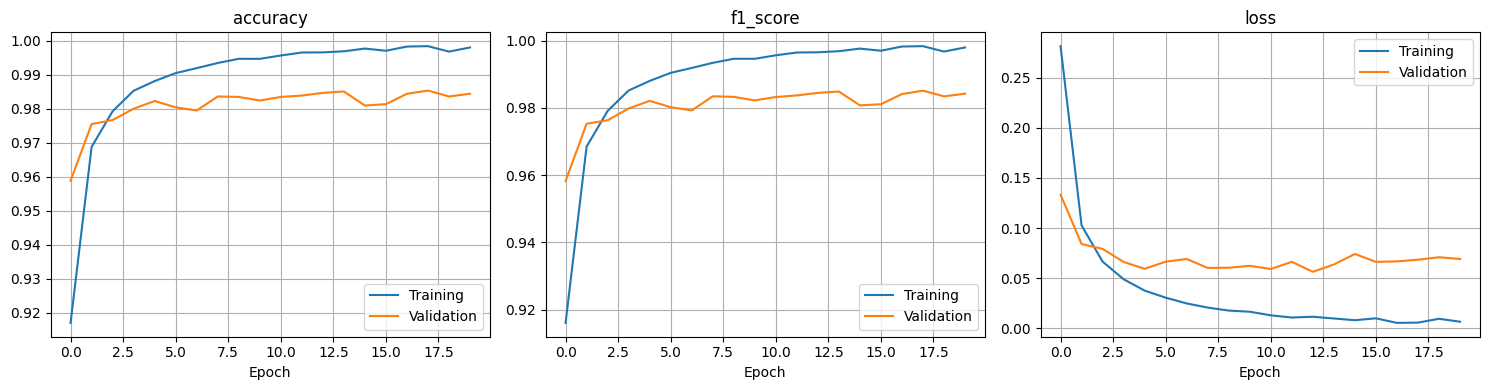

In [8]:
# Using the provided plotting methods.
plot_training_history(training)

### Task 1.2.2 Evaluate on the test dataset

In [9]:
# We received 3 values from this. First one is the loss and the last two are the accuracy and F1-metrics respectively.
lenet_model.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9878 - f1_score: 0.9878 - loss: 0.0470


[0.04696965217590332, 0.9878000020980835, 0.9877710342407227]

In [10]:
# 10000*(1-0.9878000020980835)
# Printing the shapes and flattening y labels, it causes problems otherwise.
print(y_train.shape)
print(y_test.shape)

# Converting back to label integers from one-hot encoding for confusion matrix.
y_test_true = np.argmax(y_test, axis=1)
y_train_true = np.argmax(y_train, axis=1)
print(y_train_true.shape)
print(y_test_true.shape)

(60000, 10)
(10000, 10)
(60000,)
(10000,)


### Task 2.2.3 Create a confution matrix for both traing and testing data
- Does the test data and train data predikt the same items wrong?

In [11]:
# This is from the CNN lecture - 1 slides. Adjusted the teachers' code for this.
confusion_matrix(y_train_true,np.argmax(lenet_model.predict(X_train), axis=1), labels = list(range(10)))

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


array([[5916,    1,    0,    0,    0,    0,    2,    1,    3,    0],
       [   0, 6735,    4,    0,    0,    0,    0,    1,    1,    1],
       [   2,    6, 5931,    4,    0,    0,    1,    5,    9,    0],
       [   0,    0,    4, 6110,    0,    6,    0,    1,    4,    6],
       [   0,    2,    0,    0, 5825,    0,    0,    3,    3,    9],
       [   0,    0,    0,    9,    0, 5393,    6,    0,    7,    6],
       [   2,    0,    0,    0,    2,    3, 5910,    0,    1,    0],
       [   0,    3,    2,    9,    0,    0,    0, 6241,    2,    8],
       [   4,    1,    0,    3,    1,    3,    1,    1, 5835,    2],
       [   0,    2,    0,    1,    8,    2,    2,    2,    4, 5928]])

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


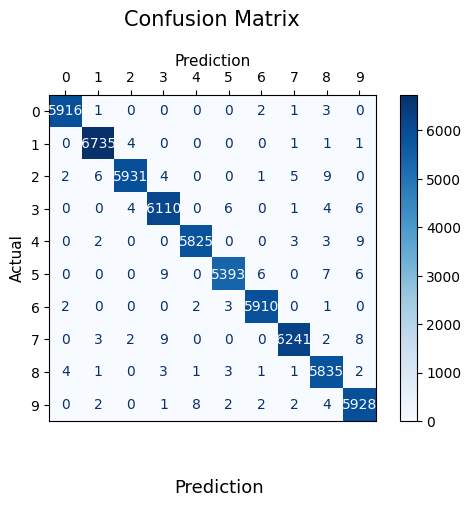

In [12]:
# Decided to also draw a graph for better visualization.
# Running model again for the plot. Running it twice because I also wanted to see the visualization above.
cm = confusion_matrix(y_train_true, np.argmax(lenet_model.predict(X_train), axis=1), labels=list(range(10)))

# Using the confusion matrix display from sklearn.
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))

# Code below is just for setting up the graph.
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix', fontsize=15, pad=20)
plt.xlabel('Prediction', fontsize=11)
plt.ylabel('Actual', fontsize=11)
plt.gca().xaxis.set_label_position('top')
plt.gca().xaxis.tick_top()
plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)

plt.show()

In [13]:
# This is from the CNN lecture - 1 slides. Adjusted the teachers' code for this.
confusion_matrix(y_test_true,np.argmax(lenet_model.predict(X_test), axis=1), labels = list(range(10)))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


array([[ 975,    0,    0,    0,    0,    0,    2,    0,    3,    0],
       [   0, 1125,    1,    1,    1,    0,    2,    2,    3,    0],
       [   1,    2, 1024,    1,    0,    0,    0,    3,    1,    0],
       [   0,    0,    2, 1000,    0,    2,    0,    0,    4,    2],
       [   0,    0,    1,    0,  965,    0,    5,    0,    1,   10],
       [   0,    0,    0,    5,    0,  885,    1,    1,    0,    0],
       [   2,    2,    0,    1,    3,    1,  947,    0,    2,    0],
       [   1,    1,    5,    4,    0,    0,    0, 1011,    2,    4],
       [   3,    0,    0,    2,    1,    2,    0,    2,  960,    4],
       [   2,    2,    1,    1,    5,    3,    1,    2,    6,  986]])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


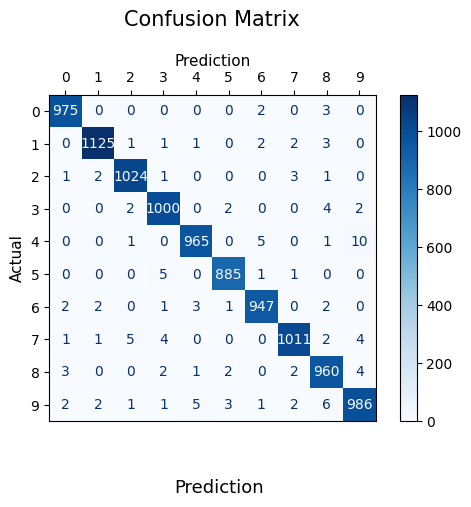

In [14]:
# Decided to also draw a graph for better visualization.
cm = confusion_matrix(y_test_true, np.argmax(lenet_model.predict(X_test), axis=1), labels=list(range(10)))

# Using the confusion matrix display from sklearn.
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=list(range(10)))

# Code below is just for setting up the graph.
disp.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix', fontsize=15, pad=20)
plt.xlabel('Prediction', fontsize=11)
plt.ylabel('Actual', fontsize=11)
plt.gca().xaxis.set_label_position('top')
plt.gca().xaxis.tick_top()
plt.gca().figure.subplots_adjust(bottom=0.2)
plt.gca().figure.text(0.5, 0.05, 'Prediction', ha='center', fontsize=13)

plt.show()

## Task 2.3: MNIST discussion

**Task 2.3.1: What is overfitting and how does it occur during training of the LeNet-5 model**

**Task 2.3.2: What is ReLU and Leaky ReLU, what is their derivative and how does their derivative solve the vanishing gradient problem?**

**Task 2.3.3: Calculate the numbers of weight and the output shape for the LeNet-5 at each layer, Show calculation**

Answer 2.3.1: Overfitting is when the model is training on the data, after certain epochs it starts to 'memorize' the data. Picking up on small details and noise. 

In the plot history of model training above, we can see that overfitting starts to occur at epoch 2. We think this because while the accuracy data curve keeps rising, validation data stagnates. This is a strong indication that the model is starting to overfit.

Answer 2.3.2: ReLu is an activation function. It basically returns the input as output if it's positive and returns zero if it's negative. Leaky ReLu is a version of ReLu which introduces a slope for the negative values. This also remedies (to a point) the 'dying ReLu' problem, in which neurons 'die' (if they return negative values, ReLu turns them into zeroes which in turn cause many null values in the network and it stops learning.)*

Since ReLu only allows positive gradients (negative values turn into zeroes), the derivates are either 0 or 1. This is an issue for tanh and sigmoid activation functions as they shrink gradients by the nature of their formulas.

When we want to train many convolution sets (conv - maxPooling - conv - maxPooling etc.) gradients vanish because we keep multiplying small values (0.1 * 0.1 etc.). However, if we make a skip connection, take it into account and take it's derivate, it would be like adding a +1 (derivative of x with respect to x is 1) to the gradient values. It would still vanish in time but it will last longer.

Answer 2.3.3: Convolution formulas are taken from lecture notes.

C1 (Conv2D) layer: 
- Input is a (28, 28, 1) MNIST image file. We Use 6 filters and "same" padding, thus the output will be (28, 28, 6)
- Input doesn't matter for weights(params). We used a (5,5) filter. (5*5) * 6 + 6 = 156.
- Explanation: Filter is 5x5 = 25 pixels (weights) and we used 6 filters thus 150. Lastly, adding the 6 for bias for each filter.

S2 (AvgPooling) layer:
- Input is (28, 28, 6) from the previous C1 layer. Using "valid" padding.
- Formula for determining the size of convolution: $o = \left \lfloor{\frac{n+2p-m}{s}}\right \rfloor +1 $ 
- $n=28\:(input),m=2\:(kernel size),p=0\:(valid\:padding),s=2\:(stride)$

    $o = \left \lfloor{\frac{28+2*0-2}{2}}\right \rfloor +1 = 14$
- Pooling output will be (14, 14, 6).
- This is a window, there are no parameters.

C3 (Conv2D) layer:
- Input is (14, 14, 6) from the previous S2 layer.
- According to formula above:
- $n=14\:(input),m=5\:(kernel size),p=0\:(valid\:padding),s=0\:(stride)$

    $o = \left \lfloor{\frac{14+2*0-5}{1}}\right \rfloor +1 = 10$ 

- Input doesn't matter for weights(params). We used a (5,5) filter. ((5*5) * 6) * 16 + 16 = 2416 params.
- Explanation: Filter is 5x5 = 25 pixels (weights) and the input came with 6 filters thus 150. This convolution layer uses 16 filter which means 2400. Lastly, adding the 16 for bias for each filter.

S4 (AvgPooling) layer:
- Input is (10, 10, 16) from the previous C3 layer.
- Formula for determining the size of convolution: $o = \left \lfloor{\frac{n+2p-m}{s}}\right \rfloor +1 $ 
- $n=10\:(input),m=2\:(kernel size),p=0\:(padding),s=2\:(stride)$

    $o = \left \lfloor{\frac{10+2*0-2}{2}}\right \rfloor +1 = 5$
- Pooling output will be (5, 5, 6).
- This is a window, there are no parameters.

Flatten layer:
- This layer simply flattens the input so it can be used by the neural network in the next layer.
- Input is (5, 5, 6) from the previous S4 layer.
- Output is simply (5*5) * 6 = 400. From a 6 dimensional input with (5,5), now we have one dimensional output with (400,) dimensions.
- There are no parameters here, this layer simply flattens the data to one dimension.

F5 Dense layer:
- This is a neural network layer. It has 120 neurons thus the output is (120,).
- Input matters in dense layer, which is (400,). 120 * 400 + 120 = 48120 params.
- Explanation: Multiplying the input with the amount of neurons and then adding the bias for each neuron.

F6 Dense layer:
- This is a neural network layer. It has 84 neurons thus the output is (84,).
- Input matters in dense layer, which is (120,). 84 * 120 + 84 = 10164 params.
- Explanation: Same as above. Multiplying the input with the amount of neurons and then adding the bias for each neuron.

Output layer:
- There are 10 output possibilities. 10 classes so the output will be (10,)
- Input matters here too, which is (84,). 10 * 84 + 10 = 850 params.
- Explanation: Same as above. Multiplying the input with the amount of neurons and then adding the bias for each neuron.

*https://www.geeksforgeeks.org/deep-learning/relu-activation-function-in-deep-learning/

*https://www.geeksforgeeks.org/machine-learning/leaky-relu-activation-function-in-deep-learning/

# Task 2: CNN for classifying the Fashion-MNIST dataset

In this task you shall implement a CNN model, and train it to classify the images in the Fashion-MNIST dataset.

## Importing Fashion-MNIST

- Filename: `Fashion_MNIST.h5`

In [15]:
# Change this path accordingly.
path = r"C:/Users/emryc/Documents/Dokumenter/NMBU/Kurs/_DAT300/DAT300/CA2/Fashion_MNIST.h5"
labels = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot" 
}

In [16]:
# Use 'path' variable here
with h5py.File(path, 'r') as f:
    print('Datasets in file:', list(f.keys()))
    X_train_f = np.asarray(f['train_images'])
    y_train_f = np.asarray(f['train_labels'])
    X_test_f  = np.asarray(f['test_images'])
    print('Nr. train images: %i' % (X_train_f.shape[0]))
    print('Nr. test images: %i' % (X_test_f.shape[0]))

Datasets in file: ['test_images', 'train_images', 'train_labels']
Nr. train images: 59500
Nr. test images: 10500


## Task 2.1: Preprocess the data
Preprocess the data as you see fit

In [17]:
print(X_train_f.shape)
print(X_test_f.shape)
print(y_train_f.shape)
# (28, 28) shows us that images are greyscale, if it was coloured it would have been (28, 28, 3) etc...

(59500, 28, 28)
(10500, 28, 28)
(59500,)


In [18]:
# Reshape data to account for color channel.
X_train_f = np.expand_dims(X_train_f, -1)
X_test_f  = np.expand_dims(X_test_f, -1)

# Normalizing input between [0,1].
X_train_f = X_train_f.astype("float32")/np.max(X_train_f)
X_test_f  = X_test_f.astype("float32")/np.max(X_test_f)

# Converting targets from numbers to categorical format. This is basically one-hot encoding.
y_train_f = ks.utils.to_categorical(y_train_f, len(np.unique(y_train_f)))
# y_test_f  = ks.utils.to_categorical(y_test, len(np.unique(y_test_f)))

# Checking the shapes again.
print(X_train_f.shape)
print(X_test_f.shape)
print(y_train_f.shape)

(59500, 28, 28, 1)
(10500, 28, 28, 1)
(59500, 10)


## Task 2.2: Visualize the dataset
Plot a few samples images and the distrbution of classes in the data. 

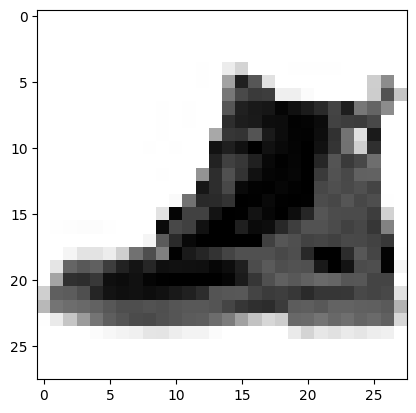

In [19]:
plt.imshow(X_train_f[1], cmap='Greys')
# I think it's an ankle boot.

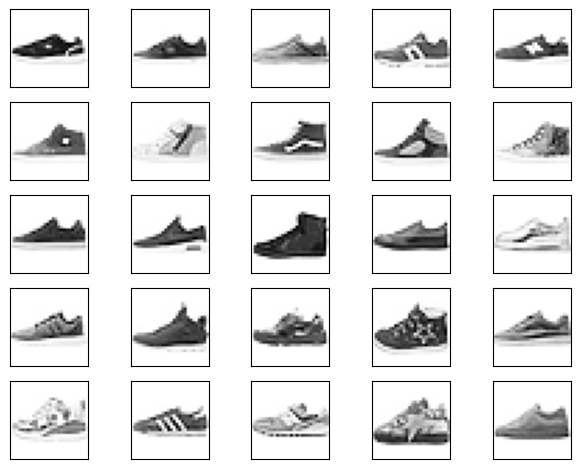

In [20]:
# We can reuse the teachers' visualization code from the last assingment. 
# Labels list in the example code above shows what kind of class the numbers represent.
# In this case pulling the class '7' from the y_train_f shows us sneakers etc...

# On line 4, needed to change the code a bit because the y_train_f is now one-hot encoded.
# Since the label 7 looks like this one-hot encoded => [0, 0, 0, 0, 0, 0, 0, 1, 0, 0], np.argmax returns the 7th index.
fig, ax = plt.subplots(nrows=5, ncols=5, sharex=True, sharey=True,)
ax = ax.flatten()
for i in range(25):
    img = X_train_f[np.argmax(y_train_f, axis=1) == 7][i].reshape(28, 28)
    ax[i].imshow(img, cmap='Greys')

ax[0].set_xticks([]); ax[0].set_yticks([])
plt.tight_layout()
plt.show()

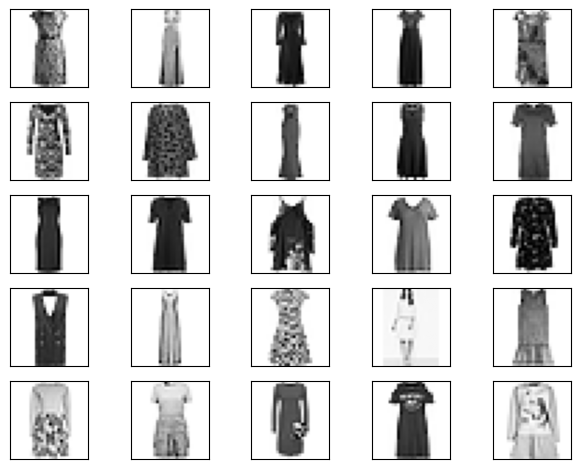

In [21]:
# If we want to see dresses, we change the class label to 3 for example.
fig, ax = plt.subplots(nrows=5, ncols=5, sharex=True, sharey=True,)
ax = ax.flatten()
for i in range(25):
    img = X_train_f[np.argmax(y_train_f, axis=1) == 3][i].reshape(28, 28, 1)
    ax[i].imshow(img, cmap='Greys')

ax[0].set_xticks([]); ax[0].set_yticks([])
plt.tight_layout()
plt.show()

In [22]:
# We can see the class distribution simply by using numpy unique.
# It shows that we have 10 classes with 5950 samples each in our training label data.

# It is the same y_train_f label set. This part just converts it back from a flattened array so we can see -
# the class distrubution for visulatization.
y_2D = y_train_f.reshape(-1, 10)    # Back to 10 classes.
y_2D = np.argmax(y_2D, axis=1)      # Pick the max value index from one-hot encoded array.

np.unique(y_2D, return_counts=True)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]),
 array([5950, 5950, 5950, 5950, 5950, 5950, 5950, 5950, 5950, 5950]))

## Task 2.3: Build a CNN for classifying the Fashion-MNIST dataset
Build a CNN model 
- Experiment with different Kernel sizes, stride, type/number of layers. 
- Don't overcomplicate and use it as grounds for discussion. 
- Tips, when you make changes to improve the model, save some earlier iterations.
- Only one model score higher than beat me.

Student's note: Decided to use keras tuner. Teacher showed keras tuner in the lesson after he finished part 1. Keras tuner is basically a hyperparameter optimizer. Instead of trying parameters ourselves we just fed them to the tuner.

In [24]:
# NEED TO INSTALL KERAS TUNER AND TENSORBOARD FOR THIS CELL TO RUN. 'pip install keras-tuner', 'pip install tensorboard'
# THIS CELL ROUGHLY TAKES 20 to 25 MINUTES TO EXECUTE.

# Copied the teachers' keras tuner code and adjusted it to our needs.
# Since the y_test labels weren't provided, we needed to make our own train and validation sets.
train_images, val_images, train_labels, val_labels = train_test_split(
    X_train_f, y_train_f, test_size=0.2, random_state=42)

# Define the model-building function for Keras Tuner.
# Currently it has a dense 10 softmax layer at the end.
# This specific keras tuner optimizes the filters, kernel size and activation function.
def build_model(hp):
    model = ks.Sequential()
    model.add(ks.layers.Input(shape=(28, 28, 1)))

    # It cycles between 1 to 2 layers and 3x3, 5x5 kernel sizes. Uses relu, leaky_relu and tanh activations.
    # Padding has been kept to 'same' to prevent too much complexity.
    for i in range(hp.Int('num_layers', min_value=1, max_value=2, step=1)):     # Adjusted the layers a bit.
        model.add(Conv2D(
            filters=hp.Int(f'filters_{i}', min_value=4, max_value=16, step=4),
            kernel_size=hp.Choice(f'kernel_size_{i}', values=[3, 5]),
            padding='same',
            activation=hp.Choice('activation', ['relu', 'leaky_relu', 'tanh'])   # Added leaky_relu to see if it would make a difference.
        ))
        # Adding a pooling layer after each convolution layer with varying strides.
        model.add(ks.layers.AveragePooling2D(
            pool_size=(2, 2), 
            strides=hp.Choice(f'strides_{i}', values=[1,2]),
        ))

    model.add(Flatten())

    # Dense layer after the convolution layers. We could also test the number of layers here but it is becoming too complex.
    model.add(Dense(
        units=hp.Int(f'units_{i}', min_value=32, max_value=256, step=32),       # I think 32 to 256 units covers enough of a range.
        activation='relu'
    ))

    # Sticking to softmax for this one. We have 10 classes so 10 neurons.
    model.add(Dense(10, activation='softmax'))

    # Tuning the learning rate for the optimizer.
    optimizer = ks.optimizers.Adam(
        hp.Float('learning_rate', 1e-4, 1e-1, sampling='log')                   # I'm leaving the learning rate like this.
    )

    model.compile(
        optimizer=optimizer,
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

# Initializing the tuner. Using RandomSearch. We know from DAT200 that Gridsearch would take forever since it compares everything.
tuner = RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=10,                           # Number of hyperparameter combinations to try. Increased it to 10.
    executions_per_trial=1,                  # Number of models to build and fit for each trial.
    directory='fashion_mnist_tuner_dir',
    project_name='fashion_mnist_tuner'
)

# Performing the hyperparameter search.
tuner.search(
    train_images, train_labels,
    epochs=10,
    validation_data=(val_images, val_labels)
)

# Get the best model.
best_model = tuner.get_best_models(num_models=1)[0]

# We are not going to evaluate the model here. It is explained above that we will create a submission csv based on model predictions.

Trial 10 Complete [00h 01m 34s]
val_accuracy: 0.9073109030723572

Best val_accuracy So Far: 0.9073109030723572
Total elapsed time: 00h 14m 29s


c:\Users\emryc\anaconda3\envs\dat300-env\lib\site-packages\keras\src\saving\saving_lib.py:868: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [25]:
# Showing results for comparison. Open the summary below in a text editor to see all the results.
tuner.results_summary()

Results summary
Results in fashion_mnist_tuner_dir\fashion_mnist_tuner
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 09 summary
Hyperparameters:
num_layers: 2
filters_0: 8
kernel_size_0: 3
activation: leaky_relu
strides_0: 2
units_0: 256
learning_rate: 0.0026724801694046137
filters_1: 16
kernel_size_1: 5
strides_1: 1
units_1: 160
Score: 0.9073109030723572

Trial 06 summary
Hyperparameters:
num_layers: 1
filters_0: 16
kernel_size_0: 5
activation: leaky_relu
strides_0: 1
units_0: 32
learning_rate: 0.0010570884819578145
filters_1: 16
kernel_size_1: 3
strides_1: 1
units_1: 32
Score: 0.9050419926643372

Trial 05 summary
Hyperparameters:
num_layers: 1
filters_0: 4
kernel_size_0: 5
activation: tanh
strides_0: 2
units_0: 192
learning_rate: 0.0012655489318837945
filters_1: 8
kernel_size_1: 3
strides_1: 1
units_1: 224
Score: 0.9008403420448303

Trial 02 summary
Hyperparameters:
num_layers: 1
filters_0: 4
kernel_size_0: 3
activation: relu
strides_0: 1
units_0: 96
l

Epoch 1/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.9471 - loss: 0.1421 - val_accuracy: 0.9032 - val_loss: 0.3158
Epoch 2/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9545 - loss: 0.1224 - val_accuracy: 0.9084 - val_loss: 0.3397
Epoch 3/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9564 - loss: 0.1168 - val_accuracy: 0.9026 - val_loss: 0.3539
Epoch 4/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9599 - loss: 0.1073 - val_accuracy: 0.9036 - val_loss: 0.3994
Epoch 5/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9622 - loss: 0.1035 - val_accuracy: 0.9098 - val_loss: 0.3730
Epoch 6/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9650 - loss: 0.0951 - val_accuracy: 0.9072 - val_loss: 0.3944
Epoch 7/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9674 - loss: 0.0911 - val_accuracy: 0.9031 - val_loss: 0.4512
Epoch 8/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.9688 - loss: 0.0829 -

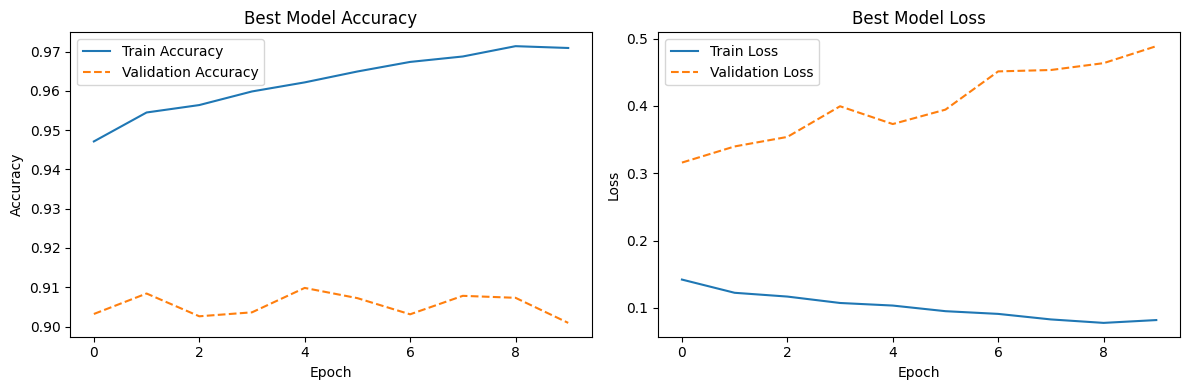

In [26]:
# Plot training & validation accuracy and loss values.
# Since Keras Tuner does not store the history object, retraining the best model to get the history.
history = best_model.fit(
    train_images, train_labels,
    epochs=10,
    validation_data=(val_images, val_labels)
)

plt.figure(figsize=(12, 4))

# Accuracy plot.
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linestyle='--')
plt.title('Best Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

# Loss plot.
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss', linestyle='--')
plt.title('Best Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# This is for comparison with older models.
# Just copy paste the saved model name from the keras_models folder.
# This is one of the better performing models, which also overfit.
old_model = load_model("keras_models/keras_best_model_2026-10-16_17-15-25.keras")

Epoch 1/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 21s 13ms/step - accuracy: 0.9930 - f1_score: 0.9930 - loss: 0.0241 - val_accuracy: 0.8991 - val_f1_score: 0.9004 - val_loss: 0.4702
Epoch 2/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9942 - f1_score: 0.9942 - loss: 0.0207 - val_accuracy: 0.8992 - val_f1_score: 0.8994 - val_loss: 0.4692
Epoch 3/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9948 - f1_score: 0.9948 - loss: 0.0183 - val_accuracy: 0.9047 - val_f1_score: 0.9048 - val_loss: 0.4791
Epoch 4/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9957 - f1_score: 0.9957 - loss: 0.0156 - val_accuracy: 0.9014 - val_f1_score: 0.9020 - val_loss: 0.5048
Epoch 5/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9964 - f1_score: 0.9964 - loss: 0.0142 - val_accuracy: 0.9000 - val_f1_score: 0.9007 - val_loss: 0.5263
Epoch 6/10
1488/1488 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9961 - f1_score: 0.9961 - loss: 0.0144 - val_accuracy: 0.902

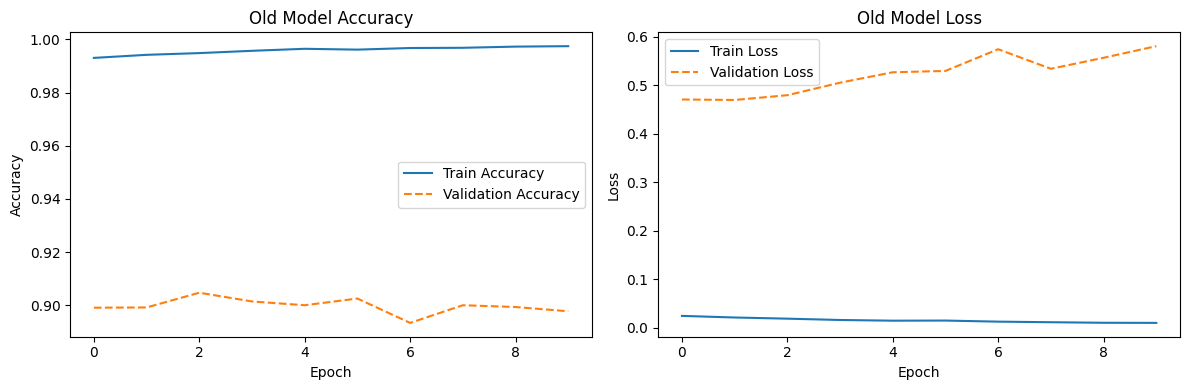

In [28]:
# Plotting the old model like we did above for comparison.
history = old_model.fit(
    train_images, train_labels,
    epochs=10,
    validation_data=(val_images, val_labels)
)

plt.figure(figsize=(12, 4))

# Accuracy plot.
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy', linestyle='--')
plt.title('Old Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()

# Loss plot.
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss', linestyle='--')
plt.title('Old Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

In [29]:
# Keras tuner creates a file directory but I'd like to save the best model anyway for further comparison.
timestamp = datetime.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

# This part is just so we can save the best models in a folder. It would also make it easier to put it in .gitignore later if needed.
dir_name = "keras_models"
os.makedirs(dir_name, exist_ok=True)

keras_best_model_name = os.path.join(dir_name, f"keras_best_model_{timestamp}.keras")
best_model.save(keras_best_model_name)
print(f"Model saved as: {keras_best_model_name}")

Model saved as: keras_models\keras_best_model_2026-10-16_18-47-05.keras


In [30]:
# Using the example to code to predict labels from X_test_f images. These predictions are written to a .csv file.
# Using the best model from keras tuner.
prediction = best_model.predict(X_test_f)
flat_prediction = np.argmax(prediction, axis=1)     # Flatten softmax predictions.
submissionDF = pd.DataFrame()
submissionDF['ID'] = range(len(flat_prediction))    # The submission csv file must have an row index column called 'ID'.
submissionDF['Prediction'] = flat_prediction
submissionDF.to_csv('submission.csv', index=False)  # Remember to store the dataframe to .csv file without the nameless index column.

329/329 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


# Task 2.5: Fashion-MNIST Discussion

### Task 2.5.1
- Feel Free to experiment on architecture
- Comment on the choice of layers and hyperparameters. 
    - Did you find some different results in changing a hyperparameter or add/remove a layer.


### Our choices for the custom architecture is as follows:
- We kept the neuron numbers between 32 and 256 to be able to get an idea how lower and higher number of neurons perform.
- We didn't manipulate the number of dense layers after the convolution layers. The cell already takes 15 to 25 minutes to execute.
- Convolution layers were kept between 1 and 2 to observe if number of layers had a significant effect.
- Learning rate was between 1e-4 and 1e-1 to observe the difference between higher and lower rates.
- We choose activation functions as follows: ReLu, Leaky ReLu and tanh. Removed sigmoid since it performs worse than these.

### Our observations:
- We added the latest tuner summary file below to show some comparisons.
- **Lower learning rate seems to perform better.** To give an example, if our function was a 2nd degree curve, higher learning rates might be missing the minimum and jumping to the other side. At the bottom of the list we can see the worst performing models. These all have high learning rates (As in bigger learning rate numbers).
- We tried relu, leaky_relu and tanh activation functions. They are very close but leaky_relu seems to pull ahead slightly. Depending on the hyperparameters ofcourse.
- 5x5 kernel size seems to be performing slightly better than 3x3.
- We didn't expect lenet to perform as well as modern architectures, which was a surprise.
- We didn't observe significant difference between the number of neurons in the dense layer.
- We also didn't observe a significant difference between high and low layer amounts.

**THE ONLY CONCRETE POINT THAT CAN BE SAID HERE IS THAT THE LEARNING RATE IS ONE OF THE MOST IMPORTANT HYPERMETERS.**
There are a lot of hyperparameters and properly compare all of them would take a lot of time. The only parameter that made major difference in model performance was the learning rate. Which can be seen at the bottom of the list below.


Results summary\
Results in fashion_mnist_tuner_dir\fashion_mnist_tuner
Showing 10 best trials
Objective(name="val_accuracy", direction="max")

Trial 09 summary\
Hyperparameters:
num_layers: 2
filters_0: 8
kernel_size_0: 3
activation: leaky_relu
strides_0: 2
units_0: 256
learning_rate: 0.0026724801694046137
filters_1: 16
kernel_size_1: 5
strides_1: 1
units_1: 160
Score: 0.9073109030723572

Trial 06 summary\
Hyperparameters:
num_layers: 1
filters_0: 16
kernel_size_0: 5
activation: leaky_relu
strides_0: 1
units_0: 32
learning_rate: 0.0010570884819578145
filters_1: 16
kernel_size_1: 3
strides_1: 1
units_1: 32
Score: 0.9050419926643372

Trial 05 summary\
Hyperparameters:
num_layers: 1
filters_0: 4
kernel_size_0: 5
activation: tanh
strides_0: 2
units_0: 192
learning_rate: 0.0012655489318837945
filters_1: 8
kernel_size_1: 3
strides_1: 1
units_1: 224
Score: 0.9008403420448303

Trial 02 summary\
Hyperparameters:
num_layers: 1
filters_0: 4
kernel_size_0: 3
activation: relu
strides_0: 1
units_0: 96
learning_rate: 0.006719715882357453
filters_1: 8
kernel_size_1: 5
strides_1: 1
units_1: 192
Score: 0.8990756273269653

Trial 01 summary\
Hyperparameters:
num_layers: 2
filters_0: 4
kernel_size_0: 3
activation: relu
strides_0: 2
units_0: 96
learning_rate: 0.0004064980478108838
filters_1: 16
kernel_size_1: 3
strides_1: 2
units_1: 224
Score: 0.8940336108207703

Trial 03 summary\
Hyperparameters:
num_layers: 1
filters_0: 12
kernel_size_0: 5
activation: tanh
strides_0: 2
units_0: 160
learning_rate: 0.0036233658831053093
filters_1: 8
kernel_size_1: 5
strides_1: 1
units_1: 192
Score: 0.8851260542869568

Trial 00 summary\
Hyperparameters:
num_layers: 2
filters_0: 12
kernel_size_0: 3
activation: leaky_relu
strides_0: 2
units_0: 192
learning_rate: 0.00010517421018398192
filters_1: 4
kernel_size_1: 3
strides_1: 1
units_1: 32
Score: 0.8379831910133362

Trial 04 summary\
Hyperparameters:
num_layers: 2
filters_0: 4
kernel_size_0: 5
activation: tanh
strides_0: 1
units_0: 224
learning_rate: 0.07457648737194063
filters_1: 8
kernel_size_1: 5
strides_1: 1
units_1: 128
Score: 0.10453781485557556

Trial 07 summary\
Hyperparameters:
num_layers: 2
filters_0: 4
kernel_size_0: 3
activation: leaky_relu
strides_0: 1
units_0: 256
learning_rate: 0.04637777670132586
filters_1: 16
kernel_size_1: 3
strides_1: 1
units_1: 64
Score: 0.10453781485557556

Trial 08 summary\
Hyperparameters:
num_layers: 2
filters_0: 8
kernel_size_0: 3
activation: relu
strides_0: 2
units_0: 64
learning_rate: 0.061575500092709456
filters_1: 8
kernel_size_1: 3
strides_1: 1
units_1: 192
Score: 0.10453781485557556
